Necessary Python Libraries

In [1]:
import os
import numpy as np
import cv2


Reading the Burst Photos

In [2]:
subfolder_path='./burst_photos'
files = [f for f in os.listdir(subfolder_path) if f.endswith(('.png', '.jpg', '.jpeg'))]


Processing the images

In [3]:
pixel_data_list=[]
greyscale_images=[]
for file_name in files:
    file_path=os.path.join(subfolder_path, file_name)
    image=cv2.imread(file_path)
    grey_photo=cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    greyscale_images.append(grey_photo)
    img_grey=cv2.imread(file_path,0)  #Reading the images in greyscale mode
    pixel_data_list.append(img_grey)
    print(f"Processed: {file_name}, Shape: {img_grey.shape}")
    #Thus created 50 numpy arrays of pixelvalues

Processed: IMG_20260323_074223_Burst01.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst02.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst03.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst04.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst05.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst06.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst07.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst08.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst09.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074223_Burst10.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074226_Burst01.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074226_Burst02.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074226_Burst03.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074226_Burst04.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074226_Burst05.jpg, Shape: (4096, 3072)
Processed: IMG_20260323_074226_Burst06.j

Displaying one of the Greyscale_images

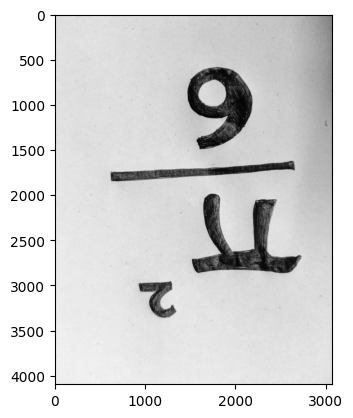

In [4]:
import matplotlib.pyplot as plt
plt.imshow(greyscale_images[2], cmap='gray')
plt.show()

Creating the Numpy Stack

In [5]:
greyscale_images_stack= np.stack(greyscale_images, axis=0)

In [13]:
pixel_series=greyscale_images_stack[:, 1000,2000]

Poisson Statistics

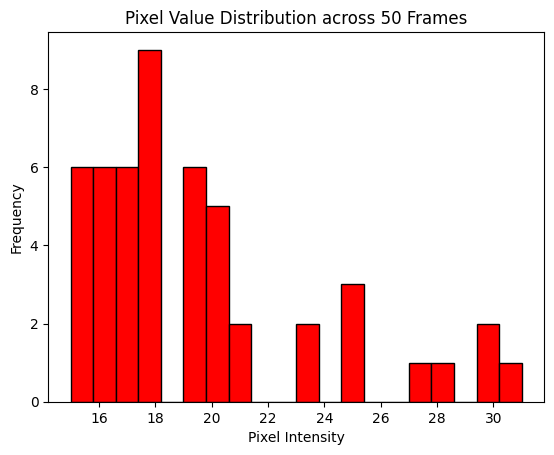

In [14]:
plt.hist(pixel_series, bins=20, color='red', edgecolor='black')
plt.title('Pixel Value Distribution across 50 Frames')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.show()

Pixel Value Analysis

In [6]:
# All the analysis will produce a single 4096*3072 numpy array of a representative photo
mean_pixel_val=np.mean(greyscale_images_stack, axis=0)


Analysis-2

In [7]:
variance_pixel_value=np.var(greyscale_images_stack, axis=0)

In [8]:
min_pixel_value=np.min(greyscale_images_stack, axis=0)
max_pixel_value=np.max(greyscale_images_stack, axis=0)

Variance Analysis

In [9]:
vmin=np.min(variance_pixel_value)
vmax=np.max(variance_pixel_value)
print(vmin)
print(vmax)
vmean=np.mean(variance_pixel_value)
print(vmean)

0.3904000000000004
6706.5764
213.74813247178395


Optional Verification for Understanding

In [10]:
type(greyscale_images_stack)
greyscale_images_stack.shape


(50, 4096, 3072)

In [11]:
type(mean_pixel_val)
mean_pixel_val.shape

(4096, 3072)

In [12]:
type(variance_pixel_value)
variance_pixel_value.shape

(4096, 3072)

In [13]:
type(min_pixel_value)
type(max_pixel_value)
min_pixel_value.shape
max_pixel_value.shape

(4096, 3072)

Detecting Regions with High Pixel Value Variance

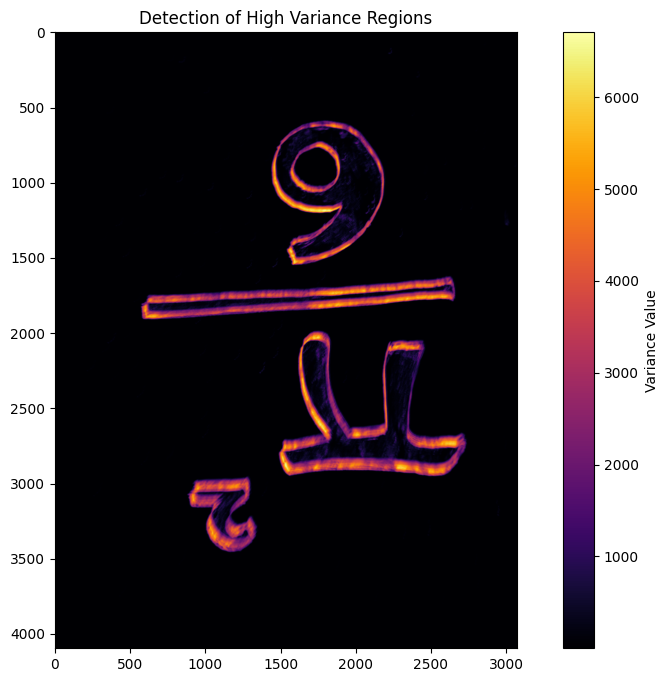

In [14]:
plt.figure(figsize=(12,8))
plt.imshow(variance_pixel_value, cmap='inferno', vmin=vmin, vmax=vmax)
plt.colorbar(label='Variance Value')
plt.title("Detection of High Variance Regions")
plt.show()


Variance Anomally in Black and White Regions

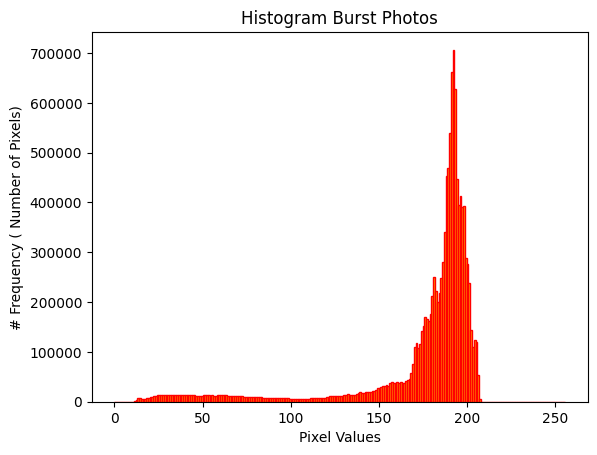

In [15]:
plt.hist(mean_pixel_val.ravel(), bins=256, range=[0,256], color='orange', edgecolor='red')
plt.title('Histogram Burst Photos')
plt.xlabel('Pixel Values')
plt.ylabel('# Frequency ( Number of Pixels)')
plt.show()

Variance Analysis(Numerical Showdown)

In [16]:
#Accessing the Coordinates with pixel value >170
coordinates_geq170= np.argwhere(mean_pixel_val > 170)

# Calculating the variance of the whitish shades
variance_pixel_value_geq170=[]
for i in coordinates_geq170:
    variance_pixel_value_geq170.append(variance_pixel_value[i[0], i[1]])

print(np.mean(variance_pixel_value_geq170))
print(np.min(variance_pixel_value_geq170))
print(np.max(variance_pixel_value_geq170))

12.651736598551059
0.3904000000000004
3214.694399999999


In [17]:
#Accessing the Coordinates with pixel value <125
coordinates_leq125= np.argwhere(mean_pixel_val <125)

# Calculating the variance of the whitish shades
variance_pixel_value_leq125=[]
for i in coordinates_leq125:
    variance_pixel_value_leq125.append(variance_pixel_value[i[0], i[1]])

print(np.mean(variance_pixel_value_leq125))
print(np.min(variance_pixel_value_leq125))
print(np.max(variance_pixel_value_leq125))

1432.2751394095428
0.8399999999999997
6706.5764


In [23]:
type(variance_pixel_value_leq125)

list

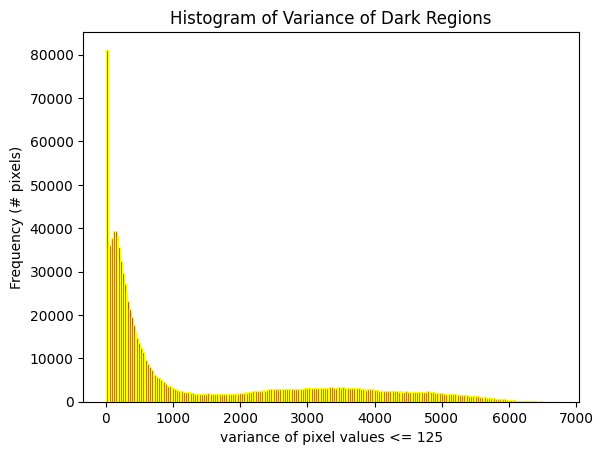

In [24]:
plt.hist(variance_pixel_value_leq125, bins=250, color='maroon', edgecolor='yellow')
plt.xlabel('variance of pixel values <= 125')
plt.ylabel('Frequency (# pixels)')
plt.title('Histogram of Variance of Dark Regions')
plt.show()

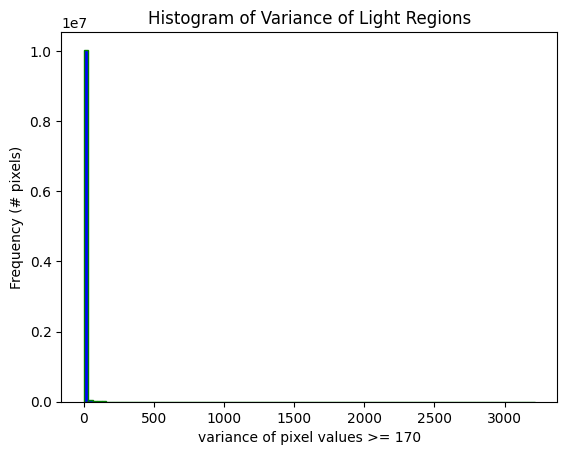

In [26]:
plt.hist(variance_pixel_value_geq170, bins=100, color='blue', edgecolor='green')
plt.xlabel('variance of pixel values >= 170')
plt.ylabel('Frequency (# pixels)')
plt.title('Histogram of Variance of Light Regions')
plt.show()

Mean Pixel value vs Pixel Value Variance 2d histogram for Analytics

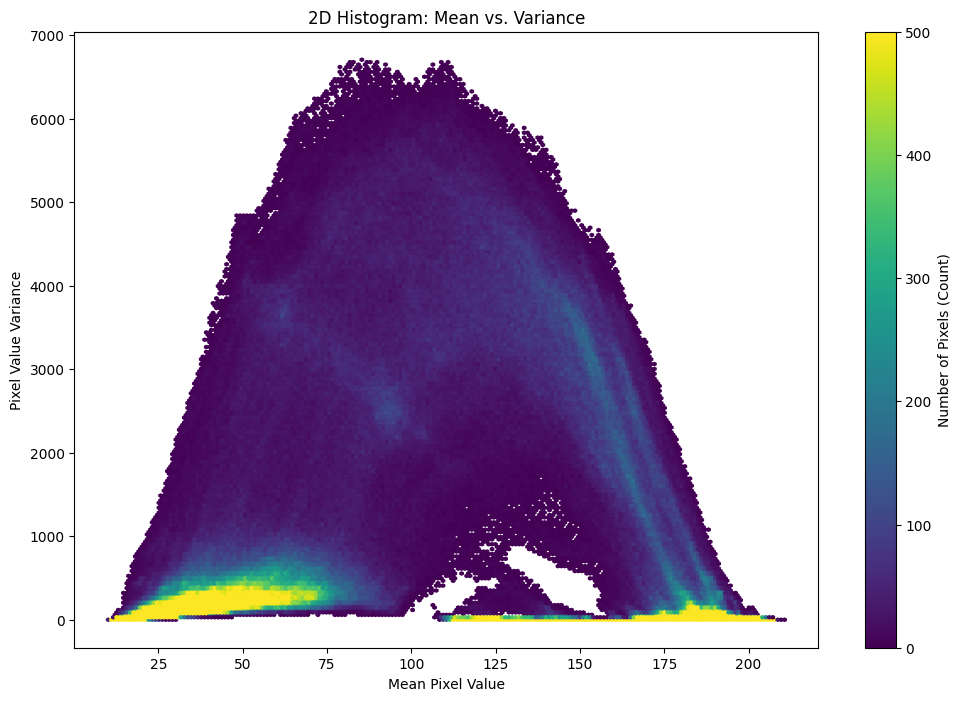

In [33]:
# 2. Flatten the arrays to 1D
# This ensures that each pixel's mean is paired with its specific variance
x = mean_pixel_val.flatten()
y = variance_pixel_value.flatten()

# 3. Create the 2D Histogram / Hexbin Plot
plt.figure(figsize=(12, 8))

# 'gridsize' controls the resolution; 'cmap' sets the color scheme
hb = plt.hexbin(x, y, gridsize=200, cmap='viridis', mincnt=1, vmin=0, vmax=500)

# Add aesthetics
plt.colorbar(hb, label='Number of Pixels (Count)')
plt.xlabel('Mean Pixel Value')
plt.ylabel('Pixel Value Variance')
plt.title('2D Histogram: Mean vs. Variance')

plt.show()

Masked Heatmap Trial (Failed effort)

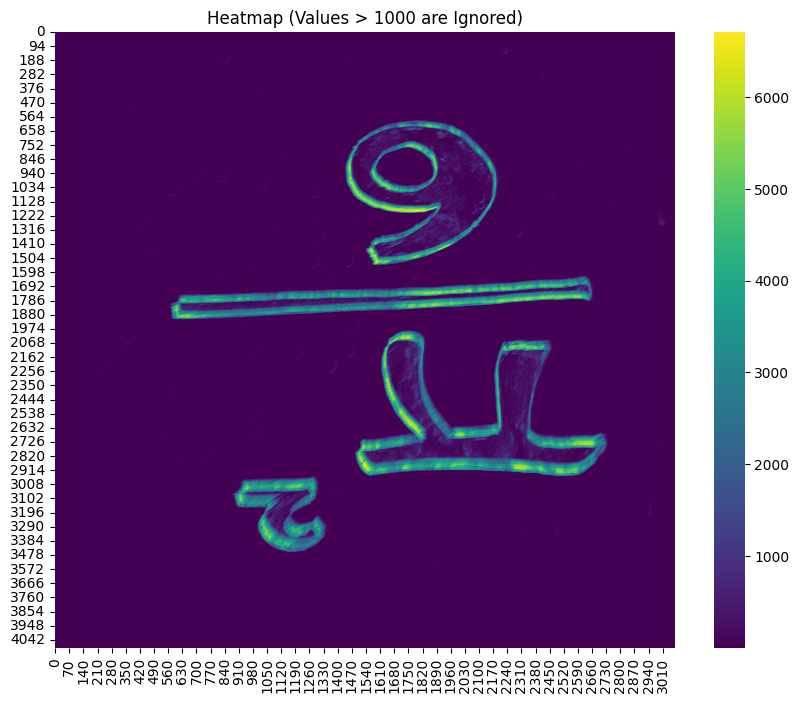

In [19]:

import seaborn as sns

# Announcing a threshold variance for mask
threshold=1000


# 2. Create a masked array where values > threshold are ignored
masked_variance_pixel_value = np.ma.masked_where(variance_pixel_value > threshold, variance_pixel_value)

# 3. Plot using Seaborn's heatmap
plt.figure(figsize=(10, 8))

# THE COLORMAP IS SPECIFIED HERE:
sns.heatmap(masked_variance_pixel_value, cmap="viridis", annot=False) 

plt.title(f"Heatmap (Values > {threshold} are Ignored)")
plt.show()

Masked Heatmap of Variance

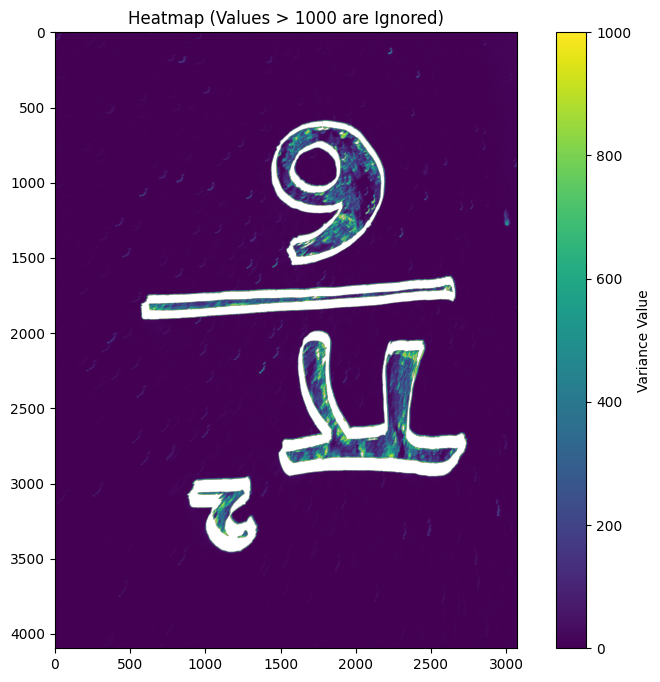

In [20]:
# Announcing a threshold variance for mask
threshold=1000


# 2. Create a masked array where values > threshold are ignored
masked_variance_pixel_value = np.ma.masked_where(variance_pixel_value > threshold, variance_pixel_value)

# 3. Plot using Seaborn's heatmap
plt.figure(figsize=(10, 8))

# THE COLORMAP IS SPECIFIED HERE:
plt.imshow(masked_variance_pixel_value, cmap="viridis", vmin=0, vmax=threshold) 
plt.colorbar(label='Variance Value')
plt.title(f"Heatmap (Values > {threshold} are Ignored)")
plt.show()

Histogram of Pixel Value Variance

In [21]:
print(np.min(variance_pixel_value))
print(np.max(variance_pixel_value))

0.3904000000000004
6706.5764


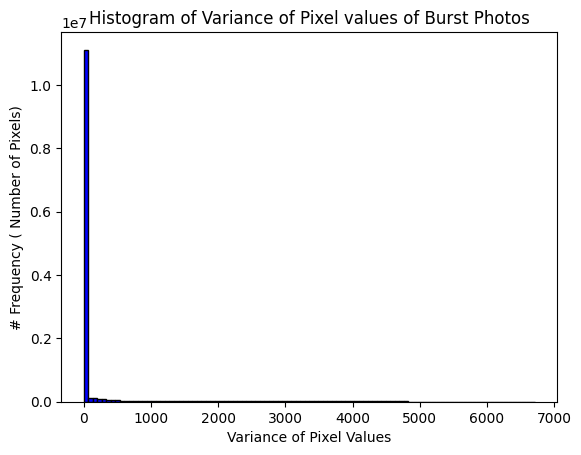

In [22]:
plt.hist(variance_pixel_value.ravel(), bins=100, range=[0,6710], color='blue', edgecolor='black')
plt.title('Histogram of Variance of Pixel values of Burst Photos')
plt.xlabel('Variance of Pixel Values')
plt.ylabel('# Frequency ( Number of Pixels)')
plt.show()